# Paper figures — what forgetting looks like *inside* the model

| # | Figure | Claim it carries
|---|---|---|
| **1** | Logit-lens depth profile, survive vs. forget-next | Forgetting is a **mid-stack** failure, not a read-out failure: the gap opens at boundary 8 and holds a 0.81–0.90 log-unit plateau from boundary 10 to the final layer
| **2** | Neuron churn before the flip + predictive AUC | The instability **precedes** the loss and adds to what the output already says: within checkpoints, neurons + internal scalars reach 0.713 against 0.694 for the scalars alone



> **The prompt caveat, shared by every figure here.** `correct` is scored on the **15-shot**
> prompt, while every internal quantity is measured on the **zero-shot** cloze, so the answer
> position is unconditioned and comparable across shot counts. Gold is the zero-shot argmax for
> only 39.8 % of correct cells. The event and the measurement live on two different prompts:
> these are statements about how a fact is *stored*, not about the decode that scored it.

## The data this notebook consumes, and how to regenerate it

Every figure is built from **three evaluation runs of `feature_extraction/eval_checkpoints.py`**
over the **13 checkpoints** of `dhgottesman/LMEnt-1B-6E` (`50 000, 100 000, … 600 000, 658 032`),
scoring the **same 1 452 facts** — the top decile of `popqa-kas` by `num_shared_chunks`
(`--top-shared-chunks-pct 10`), of which 1 310 survive the `excluded` filter. Nothing in this
notebook touches a GPU: it only reads what those runs wrote.

### The four inputs

| # | Path (relative to the repo root) | What it holds | Size | Used by |
|---|---|---|---|---|
| **1** | `data/artifacts/recall/rotemab_15shot_top10_internal/recall_step{S}_15shot_top10pct.parquet` | 13 parquets, one per checkpoint; 1 452 rows × 34 columns — `correct`, `excluded`, the output scalars (`gold_prob`, `gold_rank`, `answer_margin`, `pred_entropy`, `top1_prob`, `is_top1`, `resolution_depth`) and the per-layer arrays (`gold_rank_by_layer` = the logit lens, `mlp_*_by_layer`) | 20 MB | the `P{...}` panel and `GRL`; **Figs. 1, 3b** and the scalar baseline in **2b** |
| **2** | `15_shot_top_10_trajectory_with_fact_properites.csv` | per-fact `prop` (relation) and `num_shared_chunks` (exposure) | 196 KB | relation labels, exposure |
| **3** | `data/artifacts/expermints/15shot_trajectory_top10_internal_with_neurons/internal/neurons_step{S}_{answer,subject_last}_{idx,val}.npy` (+ `_ids.npy`, `_meta.json`) | the top-**128** active MLP neurons per (fact, checkpoint, layer, position): `uint16` indices `(1452, 18, 128)` and `float16` **signed** activations, sorted by descending \|activation\| | 4.9 GB | **Figs. 2a, 2b** |
| **4** | `data/artifacts/expermints/15shot_trajectory_top10_internal_with_hidden/` — `internal/hidden_step{S}_{answer,subject_last}.npy` (+ `_ids.npy`, `_meta.json`) and `recall/recall_step{S}_15shot_top10pct.parquet` | the raw residual stream, `float16` `(1452, 19, 2048)` per position per checkpoint (19 boundaries = embeddings + 18 blocks), plus that run's own recall tables | 2.8 GB | **Fig. 3a** |

Input 4 is **git-ignored** (its 113 MB-per-file arrays are over GitHub's limit), so a fresh clone
has to regenerate or re-download it. Inputs 1–3 are versioned.

### Regenerating them

```bash
pip install -r requirements.txt
export LMENT_DATA_ROOT=/path/to/storage        # checkpoints, corpus, artifacts land here
STEPS="50000 100000 150000 200000 250000 300000 350000 400000 450000 500000 550000 600000 658032"

# (1) the scalar / logit-lens run  -- `--no-hidden`, so only the recall parquets are written
python feature_extraction/eval_checkpoints.py --num-shots 15 --no-hidden \
    --steps $STEPS --top-shared-chunks-pct 10 \
    --output-dir $LMENT_DATA_ROOT/artifacts/recall/rotemab_15shot_top10_internal

# (3) the top-k active-neuron dump
python feature_extraction/eval_checkpoints.py --num-shots 15 --top-k 128 \
    --steps $STEPS --top-shared-chunks-pct 10 \
    --output-dir $LMENT_DATA_ROOT/artifacts/expermints/15shot_trajectory_top10_internal_with_neurons

# (4) the raw hidden-state dump (default positions: answer subject_last)
python feature_extraction/eval_checkpoints.py --num-shots 15 \
    --steps $STEPS --top-shared-chunks-pct 10 \
    --output-dir $LMENT_DATA_ROOT/artifacts/expermints/15shot_trajectory_top10_internal_with_hidden
```

Each run is one GPU forward sweep per checkpoint and is safely restartable — `--write-every`
flushes a partial parquet and an existing `recall_step{S}…parquet` is skipped — so the natural
shape is a 13-task Slurm array, one checkpoint per task.

Input **2** comes from `trajectory_analysis_rotemab_15shot_top10.ipynb`. This notebook reads only
two of its columns, so the minimal equivalent is:

```python
from datasets import load_dataset
qa = load_dataset("dhgottesman/popqa-kas")["train"].to_pandas()
qa[["id", "prop", "subject_num_chunks", "answer_num_chunks", "num_shared_chunks"]] \
  .to_csv("15_shot_top_10_trajectory_with_fact_properites.csv", index=False)
```

### The key columns, in words

- `gold_prob` — length-normalised probability of the whole gold answer: `exp(mean per-token logprob)`.
- `gold_rank` — **0-based**: how many vocabulary tokens outrank the gold token; 0 = top-1.
- `pred_entropy` — Shannon entropy (nats) of the full next-token distribution at the answer
  position. A property of the model's uncertainty, not of the label — the one feature that never
  looks at the gold answer.
- `gold_rank_by_layer` — the same rank read through the logit lens at all 19 layer boundaries.

### Three things that will bite on a fresh checkout

- **`--steps` is not optional.** `config.CHECKPOINT_STEPS` still lists the 1-epoch schedule
  (`0 … 100 000`); the 13 checkpoints analysed here belong to the **6-epoch** model
  (`config.MODEL_ID = dhgottesman/LMEnt-1B-6E`, `TOTAL_STEPS = 658032`) and must be passed explicitly.
- **Directory layout.** `--output-dir D` writes `D/recall/` and `D/internal/`. Runs 3 and 4 are
  loaded that way, but input **1** is read as a *flat* directory of parquets, as it is arranged
  locally. Keep the flat form, or point `TRAJ_DIR` one level deeper.
- **Browser-download suffixes.** Files in run 4 carry names like `hidden_step658032_answer (1).npy`
  from being downloaded out of Colab. `index_by_step()` parses the step out of the basename
  precisely so those suffixes do not matter; don't "clean up" the names expecting a glob on the
  exact filename to work.

---
## Setup and the shared panel

Style, helpers, then the fact × checkpoint panel. `excluded` (the answer leaks into the few-shot
prompt) is a property of the *fact*, so the surviving set is identical at every checkpoint and the
panel stays balanced. Two transition panels are built: `X*` over every correct → next transition,
and `A*` restricted to `t ≥ 1` so a strictly *backward* (ante-hoc) churn window exists.

In [1]:
# ── shared setup ──────────────────────────────────────────────────────────────────────
import glob, re, json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from scipy.stats import spearmanr, rankdata, mannwhitneyu

# visual style, shared with the three source notebooks
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, PURPLE, NEUTRAL = "#2a78d6", "#eb6834", "#7b5ea7", "#f0efec"
# BLUE/ORANGE is the validated pair (OKLab dE 33.6 normal, 24.7 CVD); PURPLE is the third
# hue that survives both checks.  RED is never paired with ORANGE (dE 3.6 under deuteranopia).
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
PCT = FuncFormatter(lambda v, _: f"{v:.0%}")

def clean(ax, axis="y"):
    """Recessive axes: one grid direction, no spines, no ticks."""
    ax.set_axisbelow(True)
    ax.grid(axis=axis, alpha=.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

def auc1(score, y):
    """P(score ranks a positive above a negative).  NaN-safe."""
    m = np.isfinite(score)
    score, y = score[m], np.asarray(y)[m].astype(bool)
    r = rankdata(score)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

In [2]:
# ── the fact x checkpoint panel (the `--no-hidden` internal run) ──────────────────────
TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]
FEATURES = ["correct", "is_top1", "gold_prob", "answer_margin", "gold_rank",
            "pred_entropy", "resolution_depth"]

# `excluded` (the answer leaks into the few-shot prompt) is a property of the *fact*, so the
# surviving set is identical at every checkpoint and the panel stays balanced.
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step"] + FEATURES])
long = pd.concat(frames, ignore_index=True)

P = {c: long.pivot(index="id", columns="step", values=c).reindex(columns=steps)
     for c in FEATURES}
ids = P["correct"].index
correct = P["correct"].to_numpy().astype(bool)          # (n_facts, 13)
n_facts, n_steps = correct.shape

props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv").set_index("id").reindex(ids)
prop = props["prop"].to_numpy()
exposure = props["num_shared_chunks"].to_numpy()

# Transition panels over currently-correct (fact, checkpoint) observations.
#   *F = fact row, *T = checkpoint index t (fact correct at t), *FG = wrong at t+1 (the target).
#   Parallel arrays, one per observation: P[feat].to_numpy()[XF, XT] reads that feature at the
#   still-correct checkpoint.  A fact recurs once per checkpoint it survives, hence GroupKFold.
#   X* : every transition           -- for anything measured AT or ACROSS the flip
#   A* : only t >= 1                -- so a *backward* churn cos(t-1, t) exists, i.e. the
#                                      strictly ante-hoc panel Fig. 2b is scored on
def _transitions(t0):
    f, t, y = [], [], []
    for i in range(t0, n_steps - 1):
        j = np.where(correct[:, i])[0]
        f.append(j); t.append(np.full(j.size, i)); y.append(~correct[j, i + 1])
    return np.concatenate(f), np.concatenate(t), np.concatenate(y).astype(bool)

XF, XT, XFG = _transitions(0)
AF, AT, AFG = _transitions(1)

print(f"{n_facts} scoreable facts x {n_steps} checkpoints ({steps[0]//1000}k -> {steps[-1]//1000}k)")
print(f"accuracy {correct[:, 0].mean():.1%} -> {correct[:, -1].mean():.1%}")
print(f"transitions: {XFG.size} total ({XFG.mean():.1%} forgotten next), "
      f"{AFG.size} ante-hoc ({AFG.mean():.1%})")

1310 scoreable facts x 13 checkpoints (50k -> 658k)
accuracy 14.4% -> 41.5%
transitions: 4154 total (24.1% forgotten next), 3965 ante-hoc (23.7%)


In [3]:
# ── the columns the FEATURES panel did not keep: per-layer logit-lens ranks, top1_prob ──
EXTRA = ["top1_prob", "pred_entropy", "gold_prob"]
_frames = []
for f in files:
    d = pd.read_parquet(f)
    _frames.append(d[~d["excluded"]].set_index("id").reindex(ids))
NEWP = {c: np.column_stack([fr[c].to_numpy() for fr in _frames]) for c in EXTRA}
#GRL is gold rank by layer, shape (n_facts, n_steps, n_boundaries)
GRL = np.stack([np.stack(fr["gold_rank_by_layer"].to_numpy()).astype(float)
                for fr in _frames], axis=1)          
n_bound = GRL.shape[2]

# Fix the final logit-lens boundary: the last `output_hidden_states` entry is
# already post-final-norm, but the extractor mistakenly applied the final norm
# again before the LM head. This produced ranks from a doubly-normalized state.
# Since this boundary should exactly match the model's true output distribution,
# replace it with the rank computed directly from the final logits (`gold_rank`).
# Earlier boundaries are genuinely pre-norm and therefore remain unchanged.
_true18 = np.column_stack([fr["gold_rank"].to_numpy().astype(float) for fr in _frames])
_agree = (GRL[:, :, n_bound - 1] == _true18).mean()
GRL[:, :, n_bound - 1] = _true18
print(f"gold_rank_by_layer -> {GRL.shape}  ({n_bound} layer boundaries: 0 = embeddings)")
print(f"boundary {n_bound-1} repaired from the true final-layer `gold_rank` "
      f"(the stored lens value agreed with it on only {_agree:.1%} of cells)")

gold_rank_by_layer -> (1310, 13, 19)  (19 layer boundaries: 0 = embeddings)
boundary 18 repaired from the true final-layer `gold_rank` (the stored lens value agreed with it on only 2.6% of cells)


---
# Figure 1 — forgetting is a mid-stack failure

`gold_rank_by_layer` gives the rank of the gold token under the logit lens at **every** layer
boundary, which is what turns a tautology into a localisation: the two groups are not different
everywhere, they are different in one band.

Every (fact, checkpoint) at which the fact is **correct** contributes one row, labelled by whether
it survives to the next checkpoint.

### Fig. 1a — both groups climb together, then split mid-stack

Checkpoint-balanced median $\log_{10}(\text{gold rank}+1)$ at each boundary — lower is better,
0 means the gold token is rank 1. Medians are taken *inside* each checkpoint and then averaged, so
the two groups' differing checkpoint composition cannot produce the effect. Shading marks the
mid-stack band (boundaries 8–13).

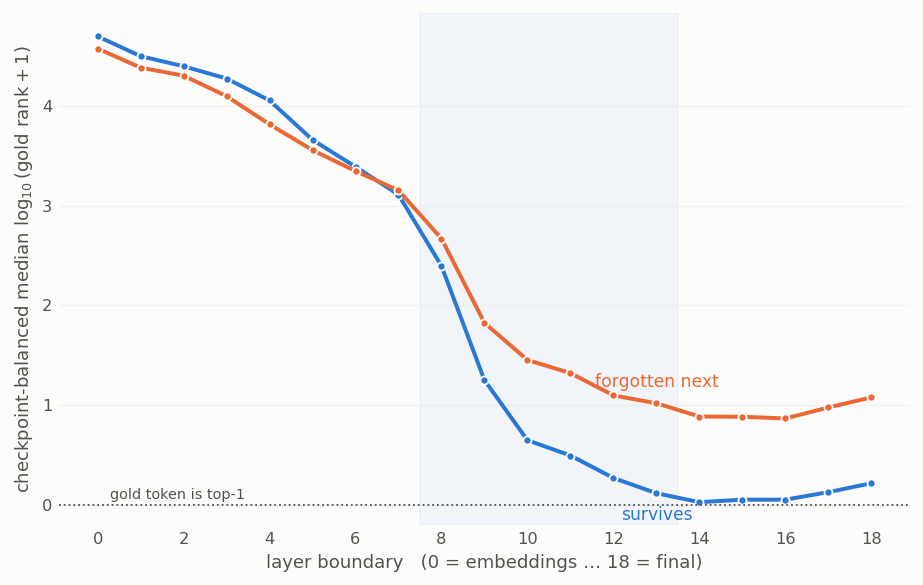

4154 transitions, forget rate 24.1%
median gold rank (back on the rank scale, 0 = top-1):
  survives : 50269.7 31747.7 25148.1 18935.3 11407.6 4589.3 2461.2 1292.2  247.8   16.8    3.4    2.1    0.9    0.3    0.1    0.1    0.1    0.3    0.6
  forgotten: 37884.4 24350.4 20237.7 12590.4 6570.1 3617.4 2230.6 1427.3  467.7   65.7   27.3   19.9   11.5    9.4    6.7    6.6    6.3    8.4   10.9


In [4]:
# ── Fig. 1a — checkpoint-balanced logit-lens depth profile  (internal §8) ────────────
# log10(rank + 1),  `gold_rank` is 0-BASED 
log_rank = np.log10(GRL + 1.0)
cur = log_rank[XF, XT]                                   # (n_transitions, n_boundaries)

def _balanced(C, T, Y):
    """Equal-weight mean of the checkpoint-specific group medians.
    Pooling all transitions would let earlier checkpoints rule forgotten while later checkpoints rule the survivors.  
    Computing the two medians INSIDE each checkpoint and then averaging gives every checkpoint equal say.
    """
    ms, mf = [], []
    for t in np.unique(T):
        m = T == t
        if (m & ~Y).any() and (m & Y).any():
            ms.append(np.nanmedian(C[m & ~Y], axis=0))
            mf.append(np.nanmedian(C[m & Y], axis=0))
    return np.nanmean(ms, axis=0), np.nanmean(mf, axis=0)

med_s, med_f = _balanced(cur, XT, XFG)
gap = med_f - med_s

# Cluster bootstrap over facts: a resampled fact contributes its whole block of transitions.
rng = np.random.default_rng(0)
uf = np.unique(XF)
# pos: fact -> all transition rows belonging to that fact
pos = {f: np.where(XF == f)[0] for f in uf}
boot = np.full((500, n_bound), np.nan)
for b in range(len(boot)):
    sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
    bs, bf = _balanced(cur[sel], XT[sel], XFG[sel])
    boot[b] = bf - bs
lo_b, hi_b = np.nanpercentile(boot, [2.5, 97.5], axis=0)

xl = np.arange(n_bound)
fig, ax1 = plt.subplots(figsize=(7.2, 4.6))
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax1.plot(xl, med_s, color=BLUE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
ax1.plot(xl, med_f, color=ORANGE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
ax1.annotate("survives", (xl[13], med_s[13]), color=BLUE, fontsize=9.5,
             xytext=(0, -15), textcoords="offset points", ha="center")
ax1.annotate("forgotten next", (xl[13], med_f[13]), color=ORANGE, fontsize=9.5,
             xytext=(0, 9), textcoords="offset points", ha="center")
ax1.axhline(0, color=INK2, lw=1, ls=":")
ax1.text(0.3, 0.06, "gold token is top-1", fontsize=8, color=INK2)
ax1.set_xlabel("layer boundary   (0 = embeddings … 18 = final)")
ax1.set_ylabel(r"checkpoint-balanced median $\log_{10}(\mathrm{gold\ rank}+1)$")
ax1.set_xticks(xl[::2])
clean(ax1)
fig.tight_layout(); plt.show()

print(f"{XFG.size} transitions, forget rate {XFG.mean():.1%}")
print("median gold rank (back on the rank scale, 0 = top-1):")
print("  survives :", " ".join(f"{10**v - 1:6.1f}" for v in med_s))
print("  forgotten:", " ".join(f"{10**v - 1:6.1f}" for v in med_f))


### Fig. 1b — a mid-stack onset, then a sustained gap

The gap between the groups, with a 95 % interval from a **cluster bootstrap over facts** — a
fact's transitions are not independent observations, so resampling transitions would understate
the interval.

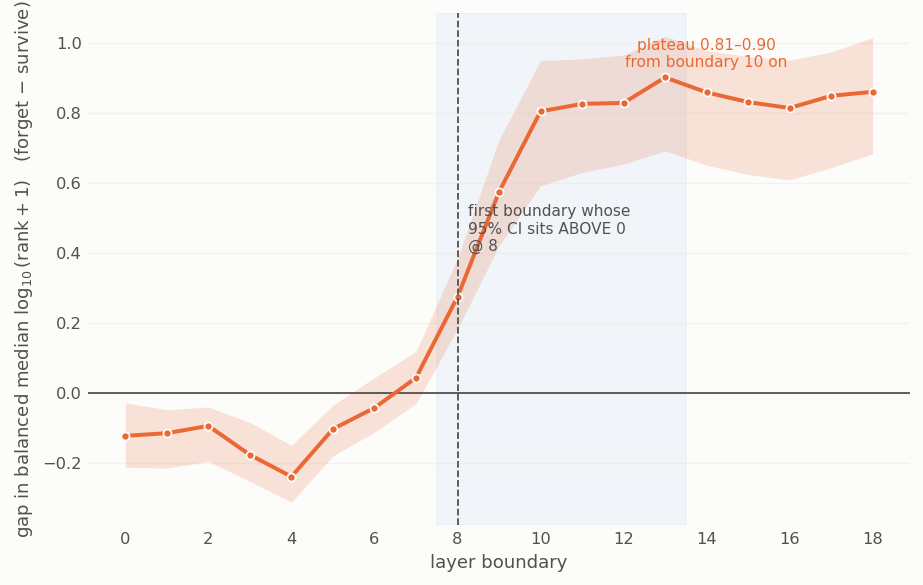

boundary:     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
gap     : -0.12 -0.12 -0.09 -0.18 -0.24 -0.10 -0.04  0.04  0.27  0.57  0.81  0.83  0.83  0.90  0.86  0.83  0.82  0.85  0.86
CI lo   : -0.21 -0.22 -0.20 -0.25 -0.31 -0.18 -0.11 -0.03  0.18  0.42  0.59  0.63  0.65  0.69  0.65  0.62  0.61  0.64  0.68

first boundary whose 95% CI clears zero: 8
largest gap: boundary 13 (0.90); boundaries 10-18 span 0.81-0.90, so this is a plateau, not a peak


In [5]:
# ── Fig. 1b — the gap between the groups, 95% cluster CI over facts  (internal §8) ────
fig, ax2 = plt.subplots(figsize=(7.2, 4.6))
ax2.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
ax2.axhline(0, color=INK2, lw=1)
ax2.fill_between(xl, lo_b, hi_b, color=ORANGE, alpha=.18, linewidth=0)
ax2.plot(xl, gap, color=ORANGE, lw=2.2, marker="o", ms=4.5, mec=SURF, mew=1)
peak = int(np.nanargmax(gap))
sig = np.where(lo_b > 0)[0]
first_sig = int(sig[0]) if len(sig) else None
if first_sig is not None:
    ax2.axvline(first_sig, color=INK2, ls="--", lw=1)
    ax2.annotate(f"first boundary whose\n95% CI sits ABOVE 0\n@ {first_sig}",  # 0-5 clear it below
                 (first_sig, gap[peak] * .45), xytext=(6, 0), textcoords="offset points",
                 fontsize=8.5, color=INK2)
# The gap is a PLATEAU from ~10 on, not a spike; annotate the range rather than a single peak.
ax2.annotate(f"plateau {gap[10:].min():.2f}–{gap[10:].max():.2f}\nfrom boundary 10 on",
             (14, gap[14]), color=ORANGE, fontsize=8.5, ha="center",
             xytext=(0, 14), textcoords="offset points")
ax2.set_xlabel("layer boundary")
ax2.set_ylabel(r"gap in balanced median $\log_{10}(\mathrm{rank}+1)$   (forget − survive)")
ax2.set_xticks(xl[::2])
clean(ax2)
fig.tight_layout(); plt.show()

print("boundary:", " ".join(f"{i:5d}" for i in xl))
print("gap     :", " ".join(f"{v:5.2f}" for v in gap))
print("CI lo   :", " ".join(f"{v:5.2f}" for v in lo_b))
print(f"\nfirst boundary whose 95% CI clears zero: {first_sig}")
print(f"largest gap: boundary {peak} ({gap[peak]:.2f}); boundaries 10-18 span "
      f"{gap[10:].min():.2f}-{gap[10:].max():.2f}, so this is a plateau, not a peak")


**Result.** 

**Boundary 8 is the
first whose interval sits entirely above zero** — that onset is the localisation. From boundary 10
the gap is a **plateau** of 0.81–0.90 log-units, still 0.86 at the final layer. On the rank scale
the median survivor reaches ≈ 0.1 (genuinely top-1) through boundaries 14–16, while the median
soon-to-be-forgotten fact never gets below ≈ 6 anywhere and ends at ≈ 11.

---
## Loading the top-128 active-neuron dump

One streaming pass over 13 checkpoints × 2 positions (~4.9 GB on disk, minutes to run). It
produces per-(fact, checkpoint, layer) summaries: state (`H`, `PR`, `L1`, `GEN`) and change
between checkpoints (`COS`, `J32`). Every churn number is then **z-scored within its
(interval, layer) column** — consecutive checkpoints are 50 k optimizer steps apart and the whole
network moves in between, so raw similarity is dominated by *which* interval it is. Standardising
within the interval asks the only fact-level question: did this fact's neurons move more than its
peers' did over the same 50 k steps?

In [6]:
# ── the top-k active-neuron dump: per-(fact, checkpoint, layer) summaries  (internal §13) ──
# Needed by Fig. 2.  One streaming pass over the 13 checkpoints x 2 positions.
NEU_DIR = Path("data/artifacts/expermints/15shot_trajectory_top10_internal_with_neurons")
_meta = json.loads((NEU_DIR / f"internal/neurons_step{steps[-1]}_meta.json").read_text())
K_NEU, n_mlp, MISSING = _meta["k"], _meta["n_layers"], _meta["missing_sentinel"]
N_INTER = 5632                      # LMEnt-1B intermediate_size
MID = slice(8, 14)                  # the mid-stack band Fig. 1 localised the failure to.

xlayer = np.arange(n_mlp)

_nids = np.load(NEU_DIR / f"internal/neurons_step{steps[-1]}_ids.npy", allow_pickle=True)
NROW = pd.Index(_nids).get_indexer(ids)                 # dump row -> panel row
assert (NROW >= 0).all(), "the neuron run does not cover every fact in the panel"

def _load(step, pos, what):
    a = np.load(NEU_DIR / f"internal/neurons_step{step}_{pos}_{what}.npy", mmap_mode="r")
    return np.asarray(a[NROW])

def _pair(iA, vA, iB, vB, k):
    """|A n B| and the cosine of two sparse activation vectors over the top-k support, for
    every (fact, layer) at once.  Concatenating the two index sets and sorting puts a shared
    neuron's two copies side by side, so one pass gives both quantities -- no k x k comparison
    and no dense 5632-wide buffer."""
    A, B = iA[..., :k].astype(np.int32), iB[..., :k].astype(np.int32)
    cat = np.concatenate([A, B], -1)
    order = np.argsort(cat, axis=-1, kind="stable")
    s = np.take_along_axis(cat, order, -1)
    eq = s[..., 1:] == s[..., :-1]        # top-k indices are distinct within a set, so an
    vs = np.take_along_axis(              # adjacent equal pair == a shared neuron
        np.concatenate([vA[..., :k], vB[..., :k]], -1), order, -1)
    dot = (vs[..., 1:] * vs[..., :-1] * eq).sum(-1)
    nrm = np.sqrt((vA[..., :k] ** 2).sum(-1) * (vB[..., :k] ** 2).sum(-1))
    return eq.sum(-1), dot / np.maximum(nrm, 1e-12)

def neuron_summaries(pos):
    """(n_facts, n_steps[-lag], n_mlp) float32 summaries.

    State at a checkpoint      H   normalised entropy of the top-k |activation|s
                               PR  participation ratio -- the effective neuron count
                               L1  total top-k activation mass
                               GEN genericity: the mean share of *other panel facts* that
                                   also have this fact's top-k neurons in theirs
    Change between checkpoints COS cosine of the sparse activation vectors, t -> t+1
                               J32 Jaccard of the top-32 index sets,        t -> t+1
    """
    n = len(ids)
    o = {k: np.full((n, n_steps, n_mlp), np.nan, np.float32) for k in ("H", "PR", "L1", "GEN")}
    o.update({k: np.full((n, n_steps - 1, n_mlp), np.nan, np.float32) for k in ("COS", "J32")})
    prev = None
    for t, s in enumerate(steps):
        I, V = _load(s, pos, "idx"), _load(s, pos, "val").astype(np.float32)
        assert (I != MISSING).all(), f"step {s} {pos}: position not located for some fact"
        a = np.abs(V); tot = a.sum(-1)
        p = a / np.maximum(tot, 1e-12)[..., None]
        o["H"][:, t] = -(p * np.log(np.maximum(p, 1e-12))).sum(-1) / np.log(K_NEU)
        o["PR"][:, t] = tot ** 2 / np.maximum((V ** 2).sum(-1), 1e-12)
        o["L1"][:, t] = tot
        for l in range(n_mlp):                     # population share of each top-k neuron
            popc = np.bincount(I[:, l, :].ravel(), minlength=N_INTER).astype(np.float32)
            # share of the OTHER facts: drop this fact's own contribution, as documented
            o["GEN"][:, t, l] = ((popc[I[:, l, :]] - 1.0) / (n - 1.0)).mean(-1)
        if prev is not None:
            _, cos = _pair(I, V, prev[0], prev[1], K_NEU)
            inter, _ = _pair(I, V, prev[0], prev[1], 32)
            o["COS"][:, t - 1] = cos
            o["J32"][:, t - 1] = inter / (64 - inter)
        prev = (I, V)
    return o

_t0 = time.time()
NA = neuron_summaries("answer")          # the token that predicts the answer
NS = neuron_summaries("subject_last")    # the subject's last token
print(f"neuron summaries in {time.time() - _t0:.0f}s: "
      f"top-{K_NEU} neurons x {n_mlp} MLP layers x 2 positions")

def within_z(M):
    """z-score each (interval, layer) column.  Consecutive checkpoints are 50k optimizer steps
    apart and the whole network moves in between, so raw similarity is dominated by *which*
    interval it is.  Standardising within the interval asks the only question that is about the
    fact: did this fact's neurons move more than its peers' did over the same 50k steps?"""
    out = np.full_like(M, np.nan)
    for t in range(M.shape[1]):
        mu, sd = np.nanmean(M[:, t], 0), np.nanstd(M[:, t], 0)
        out[:, t] = (M[:, t] - mu) / np.maximum(sd, 1e-9)
    return out

ZA_COS, ZA_J32 = within_z(NA["COS"]), within_z(NA["J32"])
ZS_COS = within_z(NS["COS"])

neuron summaries in 17s: top-128 neurons x 18 MLP layers x 2 positions


---
# Figure 2 — the instability precedes the loss, and it predicts it

**(a) Ante-hoc, not concurrent.** Similarity between $t$ and $t{+}1$ **spans** the forgetting
event, so using it to "predict" forgetting is partly circular. Fig. 2a therefore plots both: the
churn across the flip (dotted, descriptive) and the churn over the interval that **ended** at the
still-correct checkpoint (solid, strictly predictive — nothing in it can know about $t{+}1$).

**(b) Not a repackaging of "weakly stored".** Fig. 2b is 5-fold cross-validation with the **fact**
as the group (3 965 rows from 701 facts), against a real baseline — the whole block of **internal
scalar features** (gold probability, gold rank, answer margin, predictive entropy). AUC is computed
**inside each checkpoint and averaged**, because the forgetting base rate runs 13 %–48 % across
checkpoints and neuron summaries drift with training time. Both controls, or the comparison means
nothing; the pooled number is printed alongside to show the size of that correction.

### Fig. 2a — the gap is already open a full interval early

Per-layer gap in checkpoint-to-checkpoint cosine similarity of the top-128 neuron activation
vector, forgotten-next minus stays-correct, in SD units; **negative means the forgotten facts'
neurons moved more**. The per-layer verdict is in the printout rather than as ribbons (which
overlap illegibly): `*` = the whole 95 % interval is below zero, `+` = above zero, `.` = spans zero.

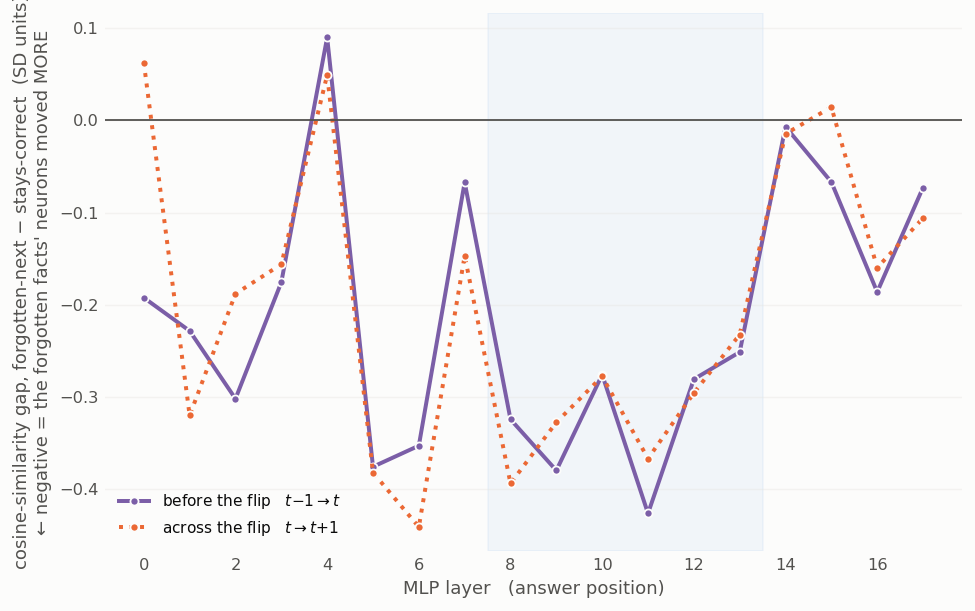

per-layer z-gap (forget − survive); negative = forgotten facts churn more
  layer       :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17
  before flip : -0.19 -0.23 -0.30 -0.18 +0.09 -0.38 -0.35 -0.07 -0.32 -0.38 -0.28 -0.43 -0.28 -0.25 -0.01 -0.07 -0.19 -0.07
  across flip : +0.06 -0.32 -0.19 -0.16 +0.05 -0.38 -0.44 -0.15 -0.39 -0.33 -0.28 -0.37 -0.30 -0.23 -0.01 +0.01 -0.16 -0.11
  95% CI      :   *      *      *      *      +      *      *      .      *      *      *      *      *      *      .      .      *      .  
mid-stack backward churn, z (higher = more stable neurons):
  forgotten next                                 n=  940   -0.044
  survives — just learned (wrong at t−1)         n=  649   +0.104
  survives — stably correct (correct at t−1)     n= 2376   +0.327
  survives — all  (the baseline plotted above)   n= 3025   +0.279
  gap vs ALL survivors            -0.323
  gap vs STABLY-CORRECT survivors -0.371   <- th

In [7]:
# ── Fig. 2a — per-layer churn gap, before vs across the flip  (internal §14a) ─────────
def churn_gap(Z, F, T, FG, lag_back=0, n_boot=300, seed=0):
    """Mean z-gap per layer (forget - survive) + a 95% CI bootstrapped over *facts*."""
    cur = Z[F, T - lag_back]
    gap = np.nanmean(cur[FG], 0) - np.nanmean(cur[~FG], 0)
    rng = np.random.default_rng(seed)
    uf = np.unique(F)
    pos = {f: np.where(F == f)[0] for f in uf}
    boot = np.empty((n_boot, Z.shape[2]))
    for b in range(n_boot):
        sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
        m = FG[sel]
        boot[b] = np.nanmean(cur[sel][m], 0) - np.nanmean(cur[sel][~m], 0)
    return gap, *np.percentile(boot, [2.5, 97.5], axis=0)

fig, ax1 = plt.subplots(figsize=(7.6, 4.8))
ax1.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
for lag, col, lab, ls in ((1, PURPLE, "before the flip   $t{-}1 \\rightarrow t$", "-"),
                          (0, ORANGE, "across the flip   $t \\rightarrow t{+}1$", ":")):
    F, T, FG = (XF, XT, XFG) if lag == 0 else (AF, AT, AFG)
    g, _, _ = churn_gap(ZA_COS, F, T, FG, lag_back=lag)
    ax1.plot(xlayer, g, color=col, lw=2.2, ls=ls, marker="o", ms=4.5, mec=SURF, mew=1, label=lab)
ax1.axhline(0, color=INK2, lw=1)
ax1.set_xticks(range(0, n_mlp, 2))
ax1.set_xlabel("MLP layer   (answer position)")
ax1.set_ylabel("cosine-similarity gap, forgotten-next − stays-correct  (SD units)\n← negative = the forgotten facts' neurons moved MORE")
ax1.legend(loc="lower left", fontsize=8.5)
clean(ax1)
fig.tight_layout(); plt.show()

g_b, lo_b2, hi_b2 = churn_gap(ZA_COS, AF, AT, AFG, lag_back=1, n_boot=200)
g_c, _, _ = churn_gap(ZA_COS, XF, XT, XFG, lag_back=0, n_boot=200)
print("per-layer z-gap (forget − survive); negative = forgotten facts churn more")
print("  layer       :", " ".join(f"{i:5d}" for i in xlayer))
print("  before flip :", " ".join(f"{v:+5.2f}" for v in g_b))
print("  across flip :", " ".join(f"{v:+5.2f}" for v in g_c))
# "*" = the whole CI is below 0 (forgotten churn more); "+" = the whole CI is ABOVE 0
# (survivors churn more -- layer 4 is the one place in the stack where that happens);
# "." = the CI spans 0.
print("  95% CI      :", "  ".join("  *  " if h < 0 else ("  +  " if l > 0 else "  .  ")
                                   for l, h in zip(lo_b2, hi_b2)))

bwd = np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1)

# Both groups are correct at t by construction, so "survives" already means "correct at t AND correct at t+1".  
# But over the *backward* window it silently mixes two kinds of survivor: facts that were already correct at t-1, and facts
# that were WRONG at t-1 and had just been learned -- and learning moves neurons too.  
# Splitting them shows the baseline is diluted, so the headline gap is conservative.
_was = correct[AF, AT - 1]
_grp = [("forgotten next", AFG),
        ("survives — just learned (wrong at t−1)", (~AFG) & ~_was),
        ("survives — stably correct (correct at t−1)", (~AFG) & _was),
        ("survives — all  (the baseline plotted above)", ~AFG)]
print("mid-stack backward churn, z (higher = more stable neurons):")
for nm, m in _grp:
    print(f"  {nm:46s} n={m.sum():5d}   {np.nanmean(bwd[m]):+.3f}")
print(f"  gap vs ALL survivors            {np.nanmean(bwd[AFG]) - np.nanmean(bwd[~AFG]):+.3f}")
print(f"  gap vs STABLY-CORRECT survivors {np.nanmean(bwd[AFG]) - np.nanmean(bwd[(~AFG) & _was]):+.3f}"
      f"   <- the cleaner contrast is LARGER, so the plotted gap understates the effect")

gpA = P["gold_prob"].to_numpy()[AF, AT]
gt = pd.qcut(gpA, 3, labels=False, duplicates="drop")
_w = [spearmanr(-bwd[gt == g], AFG[gt == g])[0] for g in range(3)]
_gw = [spearmanr(-gpA[gt == g], AFG[gt == g])[0] for g in range(3)]
print(f"\nrho(backward mid-stack churn, forgotten-next) = {spearmanr(-bwd, AFG)[0]:+.3f}")
print(f"  within gold-prob terciles: " + " ".join(f"{v:+.3f}" for v in _w) +
      f"   (mean {np.mean(_w):+.3f})")
print(f"  same for gold_prob itself: " + " ".join(f"{v:+.3f}" for v in _gw) +
      f"   (mean {np.mean(_gw):+.3f})")


### Fig. 2a supplement — splitting *both* sides of the contrast by prior state

Is the churn gap only saying that soon-to-be-forgotten facts had more often *just been learned*?
Prior state is itself a large hazard (47.0 % of just-learned facts are gone at the next checkpoint
against 13.3 % of stably-correct ones), so a pooled gap could in principle be that mixture. The
panel crosses outcome with $C_{t-1}$ into the full 2×2, all four cells correct at $t$.

**Left:** the four cell means in mid-stack backward churn, 95 % interval bootstrapped over facts.
**Right:** the Fig. 2a backward curve recomputed *inside* each prior-state stratum — if the gap were
composition, the stratified curves would collapse onto zero.

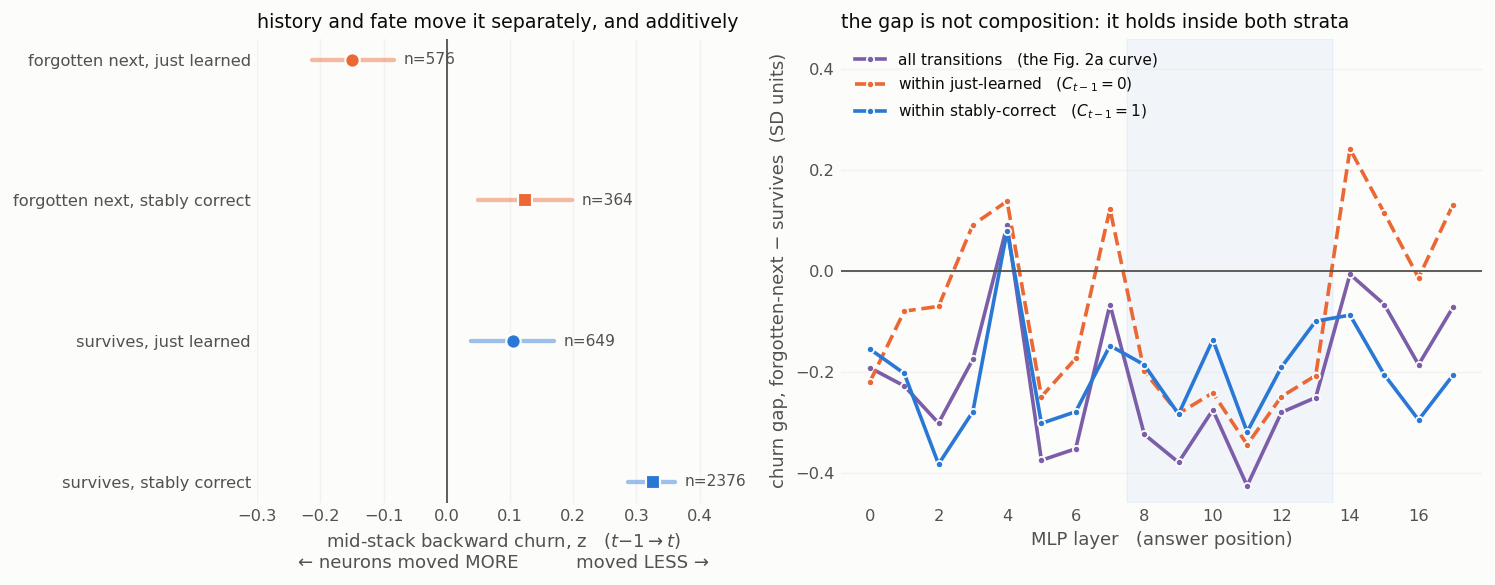

2x2 over (C_{t-1}, C_t=1, C_{t+1});  churn z: higher = this fact's neurons moved LESS
  forgotten next, just learned     n=  576 (14.5%)   churn_z -0.150   gold_prob 0.170
  forgotten next, stably correct   n=  364 ( 9.2%)   churn_z +0.124   gold_prob 0.284
  survives, just learned           n=  649 (16.4%)   churn_z +0.104   gold_prob 0.290
  survives, stably correct         n= 2376 (59.9%)   churn_z +0.327   gold_prob 0.338

the composition worry is real -- prior state is itself a strong hazard:
  just learned    (C_{t-1}=0)  n= 1225   P(forgotten next) = 47.0%
  stably correct  (C_{t-1}=1)  n= 2740   P(forgotten next) = 13.3%

...but the churn gap survives inside both strata (95% CI over facts):
  pooled          gap -0.323  [-0.378, -0.267]   *
  just learned    gap -0.254  [-0.332, -0.174]   *
  stably correct  gap -0.203  [-0.279, -0.129]   *

per-layer (right panel): how much of the stack keeps a negative gap
  all transitions          negative at 17/18 layers, CI clear of 0 at 

In [8]:
# ── Fig. 2a-supp — the 2x2: prior state x outcome  (internal §14a) ─────────────────────
# Fig. 2a contrasts "forgotten next" with "survives", both correct at t.  Over the BACKWARD
# window that ignores a second bit already in the panel: was the fact correct at t-1?  Crossing
# it with the outcome gives four cells (C_{t-1}, C_t = 1, C_{t+1}), and answers the obvious
# objection -- that the churn gap is a COMPOSITION effect, because just-learned facts both churn
# more (acquiring a fact moves its neurons) and are forgotten more.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

_was = correct[AF, AT - 1]                                   # C_{t-1}
bwd  = np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1)             # mid-stack backward churn, z
CELL22 = [("forgotten next, just learned",   AFG & ~_was, ORANGE, "o"),
          ("forgotten next, stably correct", AFG &  _was, ORANGE, "s"),
          ("survives, just learned",        ~AFG & ~_was, BLUE,   "o"),
          ("survives, stably correct",      ~AFG &  _was, BLUE,   "s")]

def _boot_fact(stat, n_boot=2000, seed=0):
    """Resample FACTS (not transitions) and recompute `stat` on the resampled row indices."""
    rng = np.random.default_rng(seed)
    uf = np.unique(AF); pos = {f: np.where(AF == f)[0] for f in uf}
    out = []
    for _ in range(n_boot):
        sel = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
        v = stat(sel)
        if np.isfinite(v):
            out.append(v)
    return np.percentile(out, [2.5, 97.5])

def cell_mean_ci(m, n_boot=600, seed=0):
    return _boot_fact(lambda s: np.nanmean(bwd[s][m[s]]), n_boot, seed)

def strat_gap(sub, n_boot=2000, seed=0):
    """Gap (forget - survive) in mid-stack backward churn INSIDE one prior-state stratum."""
    g = np.nanmean(bwd[sub & AFG]) - np.nanmean(bwd[sub & ~AFG])
    def st(s):
        y, k = AFG[s], sub[s]
        if not (y & k).any() or not (~y & k).any():
            return np.nan
        return np.nanmean(bwd[s][y & k]) - np.nanmean(bwd[s][~y & k])
    return (g, *_boot_fact(st, n_boot, seed))

def perlayer_gap(sub, n_boot=400, seed=0):
    cur = ZA_COS[AF, AT - 1]
    g = np.nanmean(cur[sub & AFG], 0) - np.nanmean(cur[sub & ~AFG], 0)
    rng = np.random.default_rng(seed)
    uf = np.unique(AF); pos = {f: np.where(AF == f)[0] for f in uf}
    boot = []
    for _ in range(n_boot):
        s = np.concatenate([pos[f] for f in rng.choice(uf, uf.size, replace=True)])
        y, k = AFG[s], sub[s]
        if not (y & k).any() or not (~y & k).any():
            continue
        boot.append(np.nanmean(cur[s][y & k], 0) - np.nanmean(cur[s][~y & k], 0))
    return g, *np.percentile(np.asarray(boot), [2.5, 97.5], axis=0)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.6, 4.6),
                               gridspec_kw={"width_ratios": [1, 1.3]})

# (left) the four cell means, each with a fact-level bootstrap interval
for k, (nm, m, col, mk) in enumerate(CELL22):
    lo, hi = cell_mean_ci(m)
    mu = np.nanmean(bwd[m])
    axL.plot([lo, hi], [k, k], color=col, lw=2.4, alpha=.45, solid_capstyle="round")
    axL.plot([mu], [k], marker=mk, ms=8, color=col, mec=SURF, mew=1.2, zorder=3)
    axL.text(hi + .015, k, f"n={m.sum()}", va="center", fontsize=8.5, color=INK2)
axL.axvline(0, color=INK2, lw=1)
axL.set_yticks(range(4), [nm for nm, *_ in CELL22], fontsize=9)
axL.invert_yaxis()
axL.set_xlim(-.30, .48)
axL.set_xlabel("mid-stack backward churn, z   ($t{-}1 \\rightarrow t$)\n← neurons moved MORE          moved LESS →")
axL.set_title("history and fate move it separately, and additively", fontsize=10.5, loc="left")
clean(axL, axis="x")

# (right) the Fig. 2a backward curve, recomputed inside each prior-state stratum
axR.axvspan(7.5, 13.5, color=BLUE, alpha=.05, zorder=0)
STRATA = (("all transitions   (the Fig. 2a curve)", np.ones_like(_was, bool), PURPLE, "-"),
          ("within just-learned   ($C_{t-1}{=}0$)", ~_was, ORANGE, "--"),
          ("within stably-correct   ($C_{t-1}{=}1$)", _was, BLUE, "-"))
PL = {}
for nm, sub, col, ls in STRATA:
    PL[nm] = g, lo, hi = perlayer_gap(sub)
    axR.plot(xlayer, g, color=col, lw=2.0, ls=ls, marker="o", ms=4, mec=SURF, mew=1, label=nm)
axR.axhline(0, color=INK2, lw=1)
axR.set_xticks(range(0, n_mlp, 2))
axR.set_xlabel("MLP layer   (answer position)")
axR.set_ylabel("churn gap, forgotten-next − survives  (SD units)")
axR.set_title("the gap is not composition: it holds inside both strata", fontsize=10.5, loc="left")
axR.set_ylim(top=0.46)                       # headroom so the legend clears the curves
axR.legend(loc="upper left", fontsize=8.5, ncol=1)
clean(axR)
fig.tight_layout(); plt.show()

gpA_ = P["gold_prob"].to_numpy()[AF, AT]
print("2x2 over (C_{t-1}, C_t=1, C_{t+1});  churn z: higher = this fact's neurons moved LESS")
for nm, m, *_ in CELL22:
    print(f"  {nm:32s} n={m.sum():5d} ({m.mean():5.1%})   churn_z {np.nanmean(bwd[m]):+.3f}"
          f"   gold_prob {np.nanmean(gpA_[m]):.3f}")

print("\nthe composition worry is real -- prior state is itself a strong hazard:")
for nm, m in (("just learned    (C_{t-1}=0)", ~_was), ("stably correct  (C_{t-1}=1)", _was)):
    print(f"  {nm:28s} n={m.sum():5d}   P(forgotten next) = {AFG[m].mean():5.1%}")

print("\n...but the churn gap survives inside both strata (95% CI over facts):")
for nm, sub in (("pooled        ", np.ones_like(_was, bool)),
                ("just learned  ", ~_was), ("stably correct", _was)):
    g, lo, hi = strat_gap(sub)
    print(f"  {nm}  gap {g:+.3f}  [{lo:+.3f}, {hi:+.3f}]" + ("   *" if hi < 0 or lo > 0 else "   n.s."))

print("\nper-layer (right panel): how much of the stack keeps a negative gap")
for nm, *_ in STRATA:
    g, lo, hi = PL[nm]
    print(f"  {nm.split('(')[0].strip():24s} negative at {int((g < 0).sum()):2d}/18 layers,"
          f" CI clear of 0 at {int((hi < 0).sum()):2d}/18   (survivors churn more at"
          f" {int((lo > 0).sum())})")

_cm = {(a, b): np.nanmean(bwd[(_was == a) & (AFG == b)]) for a in (0, 1) for b in (0, 1)}
_ic = lambda c: (c[(1, 0)] - c[(1, 1)]) - (c[(0, 0)] - c[(0, 1)])
_ilo, _ihi = _boot_fact(lambda s: _ic({(a, b): np.nanmean(bwd[s][(_was[s] == a) & (AFG[s] == b)])
                                       for a in (0, 1) for b in (0, 1)}))
print(f"  main effect, just learned   {(_cm[(0,0)]+_cm[(0,1)])/2 - (_cm[(1,0)]+_cm[(1,1)])/2:+.3f}"
      "   (acquiring a fact moves its neurons too)")
print(f"  main effect, forgotten next {(_cm[(0,1)]+_cm[(1,1)])/2 - (_cm[(0,0)]+_cm[(1,0)])/2:+.3f}")
print(f"  interaction                 {_ic(_cm):+.3f}  [{_ilo:+.3f}, {_ihi:+.3f}]"
      + ("   significant" if _ilo > 0 or _ihi < 0 else "   n.s. -- the two effects are ADDITIVE"))

def _oof(X):
    X = np.asarray(X, float); o = np.full(len(X), np.nan)
    for tr, te in GroupKFold(n_splits=5).split(X, AFG, groups=AF):
        o[te] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)) \
                .fit(X[tr], AFG[tr]).predict_proba(X[te])[:, 1]
    return o

def _auc_within(o):
    return float(np.mean([roc_auc_score(AFG[AT == t], o[AT == t])
                          for t in np.unique(AT) if 0 < AFG[AT == t].mean() < 1]))

_pri, _chn, _gp = (~_was).astype(float), -bwd, -gpA_
print("\nwithin-checkpoint AUC for 'forgotten at t+1', out-of-fold, grouped by fact:")
for nm, X in (("prior state alone (one bit)",  _pri[:, None]),
              ("backward churn alone",         _chn[:, None]),
              ("gold probability alone",       _gp[:, None]),
              ("prior state + churn",          np.column_stack([_pri, _chn])),
              ("prior state + gold prob",      np.column_stack([_pri, _gp])),
              ("all three",                    np.column_stack([_pri, _chn, _gp]))):
    print(f"  {nm:30s} {_auc_within(_oof(X)):.3f}")

print("\nwithin-checkpoint AUC of backward churn alone, computed INSIDE one stratum:")
for nm, sub in (("just learned  ", ~_was), ("stably correct", _was)):
    per = [auc1(-bwd[sub & (AT == t)], AFG[sub & (AT == t)])
           for t in np.unique(AT)
           if (sub & (AT == t)).sum() > 30 and 0 < AFG[sub & (AT == t)].mean() < 1]
    print(f"  {nm} {np.mean(per):.3f}   ({len(per)} checkpoints)")

### Fig. 2b — neurons add to the internal scalar features, they do not beat them

Out-of-fold AUC for predicting "forgotten at the next checkpoint": 5-fold cross-validation grouped
by **fact**, scored **inside each checkpoint** and averaged.

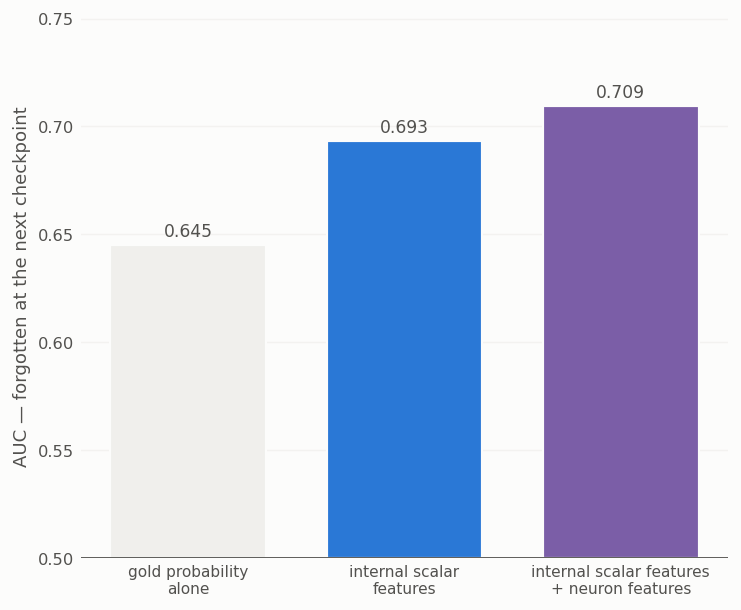


3965 ante-hoc transitions from 701 facts, base rate 23.7%
  block                      within-ckpt   pooled     per-ckpt range
  gold probability alone           0.645    0.634       [0.571, 0.745]
  internal scalar features         0.693    0.680       [0.571, 0.817]
  neuron features alone            0.684    0.711       [0.563, 0.784]
  internal scalar features + neuron features       0.709    0.740       [0.621, 0.835]
  neurons vs internal scalars: within-checkpoint -0.010, pooled +0.031
  both vs internal scalars   : within-checkpoint +0.016, pooled +0.060


In [9]:
# ── Fig. 2b — do the neurons say anything the internal scalars do not?  (internal §16) ──
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

def band(D, key, sl, back=0):
    return np.nanmean(D[key][AF, AT - back][:, sl], 1)

OUT_SCALARS = {                       # everything the scalar analysis already had
    "gold probability":   -P["gold_prob"].to_numpy()[AF, AT],
    "gold rank":           np.log10(P["gold_rank"].to_numpy()[AF, AT] + 1.0),
    "answer margin":      -P["answer_margin"].to_numpy()[AF, AT],
    "predictive entropy":  P["pred_entropy"].to_numpy()[AF, AT],
}
NEURON_SCALARS = {                    # new, from the top-128 dump; all measured at or before t
    "churn, answer (mid)":      -np.nanmean(ZA_COS[AF, AT - 1][:, MID], 1),
    "churn, answer (early)":    -np.nanmean(ZA_COS[AF, AT - 1][:, :8], 1),
    "churn, answer (late)":     -np.nanmean(ZA_COS[AF, AT - 1][:, 14:], 1),
    "churn, subject (mid)":     -np.nanmean(ZS_COS[AF, AT - 1][:, MID], 1),
    "top-32 churn (mid)":       -np.nanmean(ZA_J32[AF, AT - 1][:, MID], 1),
    "diffuse activation (mid)":  band(NA, "PR", MID),
    "high activation entropy":   band(NA, "H", MID),
    "private neurons (mid)":    -band(NA, "GEN", MID),
    "shared neurons (late)":     band(NA, "GEN", slice(12, 16)),
    "large activation mass":     np.log10(np.clip(band(NA, "L1", MID), 1, None)),
}
X_out = np.column_stack(list(OUT_SCALARS.values()))
X_neu = np.column_stack(list(NEURON_SCALARS.values()))

def cv_oof(X):
    """Out-of-fold scores with the FACT as the group, so a fact never straddles a split.
    Imputation and scaling are fit INSIDE each training fold rather than globally."""
    X = np.asarray(X); oof = np.full(len(X), np.nan)
    for tr, te in GroupKFold(n_splits=5).split(X, AFG, groups=AF):
        m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(max_iter=3000)).fit(X[tr], AFG[tr])
        oof[te] = m.predict_proba(X[te])[:, 1]
    return oof

def auc_within(oof):
    """AUC computed INSIDE each checkpoint, then averaged.

    Grouping by fact stops fact leakage but NOT checkpoint leakage, and
    this panel has to obey that too.  The forgetting rate runs 13%-48% across checkpoints, so a
    feature that merely encodes training time separates the pooled classes without separating
    anything within a checkpoint.  Pooled AUC is printed alongside only to show that gap.
    """
    per = [roc_auc_score(AFG[AT == t], oof[AT == t])
           for t in np.unique(AT) if 0 < AFG[AT == t].mean() < 1]
    return float(np.mean(per)), np.asarray(per)

BLOCKS = [("gold probability\nalone", X_out[:, :1], NEUTRAL),
          ("internal scalar\nfeatures", X_out, BLUE),
          ("neuron features\nalone", X_neu, ORANGE),
          ("internal scalar features\n+ neuron features",
           np.column_stack([X_out, X_neu]), PURPLE)]
SHOWN = [0, 1, 3]
oofs = [cv_oof(X) for _, X, _ in BLOCKS]
AUC_DETAIL = [auc_within(o) for o in oofs]               # the honest, checkpoint-adjusted number
aucs = [v[0] for v in AUC_DETAIL]
aucs_pooled = [roc_auc_score(AFG, o) for o in oofs]      # what pooling across checkpoints inflates it to

fig, ax2 = plt.subplots(figsize=(5.8, 4.8))
xb = list(range(len(SHOWN)))
ax2.bar(xb, [aucs[i] - .5 for i in SHOWN], bottom=.5,     # bar length = lift over chance
        color=[BLOCKS[i][2] for i in SHOWN], edgecolor=SURF, linewidth=1.2, width=.72)
for j, i in enumerate(SHOWN):
    ax2.text(j, aucs[i] + .004, f"{aucs[i]:.3f}", ha="center", fontsize=9.5, color=INK2)
ax2.axhline(0.5, color=INK2, lw=1)
ax2.set_xticks(xb, [BLOCKS[i][0] for i in SHOWN], fontsize=8.5)
ax2.set_ylim(0.5, max(aucs[i] for i in SHOWN) * 1.06)
ax2.set_ylabel("AUC — forgotten at the next checkpoint")
clean(ax2)
fig.tight_layout(); plt.show()

print(f"\n{AFG.size} ante-hoc transitions from {len(np.unique(AF))} facts, base rate {AFG.mean():.1%}")
print(f"  {'block':26s} {'within-ckpt':>11s} {'pooled':>8s} {'per-ckpt range':>18s}")
for (nm, _, _), (v, per), w in zip(BLOCKS, AUC_DETAIL, aucs_pooled):
    print(f"  {nm.replace(chr(10), ' '):26s} {v:11.3f} {w:8.3f} "
          f"      [{per.min():.3f}, {per.max():.3f}]")
print(f"  neurons vs internal scalars: within-checkpoint {aucs[2] - aucs[1]:+.3f}, "
      f"pooled {aucs_pooled[2] - aucs_pooled[1]:+.3f}")
print(f"  both vs internal scalars   : within-checkpoint {aucs[3] - aucs[1]:+.3f}, "
      f"pooled {aucs_pooled[3] - aucs_pooled[1]:+.3f}")


**Result — Fig. 2a.** The backward curve, which cannot be an echo of the flip, is almost
superimposed on the concurrent one, and around MLP layer 11 it is *deeper*. Layer 11 writes into
boundary 12, inside the plateau Fig. 1 finds from boundary 10 on — two independent measurements,
one from the output projection and one from the raw activations, agree on the region.

The honest framing is that **instability is diffuse**: the gap is negative at 17 of 18 layers
(13 with the interval clear of zero) and is as deep at layers 1–3 and 5–6 as inside the mid-stack
band. Localisation rests on Fig. 1; Fig. 2a corroborates the depth range, not the localisation.
One layer reverses — at **layer 4 the survivors churn significantly more**.

**Result — the 2×2.** The gap is *not* a composition artifact: it holds inside both strata with the
fact-level interval clear of zero, and the interaction is **−0.051 [−0.17, +0.07], n.s.** — the two
effects are **additive** (being just-learned costs ≈ 0.25 SD of stability, being doomed a further
≈ 0.23 SD). Against stably-correct survivors alone the gap widens from −0.323 to −0.371, so the
plotted baseline is diluted and the headline number is conservative.

**Result — Fig. 2b.** Pooled across checkpoints the neuron block reaches 0.711 against
0.681 for the scalars. The neuron dump may carry information about the next
flip that the output distribution does not, without ever seeing the vocabulary.